# Employment Trends in AI, Data Science and Software Development

## Introduction
This research looks into employment trends in software development, data science, and artificial intelligence (AI) fields in the US.

The U.S. Bureau of Labor Statistics (BLS) Occupational Employment and Wage Statistics (OEWS) datasets for 2022, 2023, 2024, and 2025 are used in the research.

The data is prepared, analyzed, and visualized using Python modules such as Pandas, NumPy, Matplotlib, and Seaborn.

This study aims to determine employment patterns over time, analyze annual salary disparities, and compare employment levels across technology-related occupations.

**Scope:** The chosen professions have to do with artificial intelligence and the technologies that support it. The number of persons working specifically in AI is not directly measured by the datasets.

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")


Libraries imported successfully!


## Data Sources and Preparation
The employment data used in this project was obtained from the U.S. Bureau of Labor Statistics (BLS) Occupational Employment and Wage Statistics (OEWS) programme.

The datasets cover the years 2022, 2023, 2024 and 2025. They contain information about occupational employment estimates, occupation titles, industry classifications and annual wage estimates.

The data will be inspected and prepared using Pandas before being used to create visualisations.

The 2023 dataset contains a larger number of records than the other years. Therefore, the relevant national employment records will be selected to ensure that comparisons across years are consistent.

**Source:** U.S. Bureau of Labor Statistics. Occupational Employment and Wage Statistics. https://www.bls.gov/oes/tables.htm

In [7]:
# Inspect the national records in each dataset

for year, df in {
    2022: data_2022,
    2023: data_2023,
    2024: data_2024,
    2025: data_2025
}.items():
    print(f"\n{year}")
    print(df["AREA_TITLE"].value_counts().head())


2022
AREA_TITLE
U.S.    1402
Name: count, dtype: int64

2023
AREA_TITLE
U.S.            177501
California         836
Texas              830
Pennsylvania       814
Michigan           813
Name: count, dtype: int64

2024
AREA_TITLE
U.S.    1403
Name: count, dtype: int64

2025
AREA_TITLE
U.S.    1401
Name: count, dtype: int64


In [12]:
# Organise the four datasets

datasets = {
    2022: data_2022,
    2023: data_2023,
    2024: data_2024,
    2025: data_2025
}

# Filter all datasets to national U.S. records

national_datasets = {}

for year, df in datasets.items():

    national_datasets[year] = df[
        df["AREA_TITLE"] == "U.S."
    ].copy()

    print(
        year,
        "National records:",
        len(national_datasets[year])
    )

2022 National records: 1402
2023 National records: 177501
2024 National records: 1403
2025 National records: 1401


In [13]:
# Select three technology-related occupations

selected_occupations = [
    "15-1212",  # Information Security Analysts
    "15-1252",  # Software Developers
    "15-2051"   # Data Scientists
]

for year, df in national_datasets.items():

    print(f"\n--- {year} ---")

    results = df[
        df["OCC_CODE"].isin(selected_occupations)
    ][["OCC_CODE", "OCC_TITLE"]].drop_duplicates()

    print(results.to_string(index=False))


--- 2022 ---
OCC_CODE                     OCC_TITLE
 15-1212 Information Security Analysts
 15-1252           Software Developers
 15-2051               Data Scientists

--- 2023 ---
OCC_CODE                     OCC_TITLE
 15-1212 Information Security Analysts
 15-1252           Software Developers
 15-2051               Data Scientists

--- 2024 ---
OCC_CODE                     OCC_TITLE
 15-1212 Information Security Analysts
 15-1252           Software Developers
 15-2051               Data Scientists

--- 2025 ---
OCC_CODE                     OCC_TITLE
 15-1212 Information Security Analysts
 15-1252           Software Developers
 15-2051               Data Scientists


In [14]:
# Build a combined employment and wage dataset

comparison_data = []

for year, df in national_datasets.items():

    selected = df[
        df["OCC_CODE"].isin(selected_occupations)
    ].copy()

    for _, row in selected.iterrows():

        comparison_data.append({
            "Year": year,
            "Occupation": row["OCC_TITLE"],
            "Occupation_Code": row["OCC_CODE"],
            "Employment": row["TOT_EMP"],
            "Median_Annual_Wage": pd.to_numeric(
                row["A_MEDIAN"], errors="coerce"
            )
        })

comparison_df = pd.DataFrame(comparison_data)

comparison_df

,Year,Occupation,Occupation_Code,Employment,Median_Annual_Wage
0,2022,Information Security Analysts,15-1212,163690,112000.0
1,2022,Software Developers,15-1252,1534790,127260.0
2,2022,Data Scientists,15-2051,159630,103500.0
3,2023,Information Security Analysts,15-1212,175350,120360.0
4,2023,Software Developers,15-1252,1656880,132270.0
...,...,...,...,...,...
893,2024,Software Developers,15-1252,1654440,133080.0
894,2024,Data Scientists,15-2051,233440,112590.0
895,2025,Information Security Analysts,15-1212,190650,129180.0
896,2025,Software Developers,15-1252,1687890,135980.0


In [15]:
# Check the completed comparison dataset

print("Number of records:", len(comparison_df))
print("\nMissing values:")
print(comparison_df.isnull().sum())

print("\nDataset information:")
comparison_df.info()

Number of records: 898

Missing values:
Year                  0
Occupation            0
Occupation_Code       0
Employment            0
Median_Annual_Wage    7
dtype: int64

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 898 entries, 0 to 897
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Year                898 non-null    int64  
 1   Occupation          898 non-null    str    
 2   Occupation_Code     898 non-null    str    
 3   Employment          898 non-null    object 
 4   Median_Annual_Wage  891 non-null    float64
dtypes: float64(1), int64(1), object(1), str(2)
memory usage: 59.2+ KB


In [16]:
# Investigate duplicate occupation records

for year, df in national_datasets.items():

    selected = df[
        df["OCC_CODE"].isin(selected_occupations)
    ]

    print(f"\n--- {year} ---")

    print("NAICS values:")
    print(selected["NAICS"].value_counts().head(10))

    print("\nOwnership values:")
    print(selected["OWN_CODE"].value_counts())

    print("\nIndustry titles:")
    print(selected["NAICS_TITLE"].value_counts().head(10))


--- 2022 ---
NAICS values:
NAICS
0    3
Name: count, dtype: int64

Ownership values:
OWN_CODE
1235    3
Name: count, dtype: int64

Industry titles:
NAICS_TITLE
Cross-industry    3
Name: count, dtype: int64

--- 2023 ---
NAICS values:
NAICS
611000    12
622000    12
622100    12
611300    11
611200     9
611100     8
611700     8
611500     7
622300     7
455000     6
Name: count, dtype: int64

Ownership values:
OWN_CODE
5       754
235      37
3        26
2        23
57       21
1        10
123       9
1235      3
58        3
59        3
Name: count, dtype: int64

Industry titles:
NAICS_TITLE
Educational Services                                            15
Hospitals                                                       12
General Medical and Surgical Hospitals                          12
Colleges, Universities, and Professional Schools                11
Management of Companies and Enterprises                          9
Junior Colleges                                                 

In [17]:
# Filter national, cross-industry, all-ownership records

clean_datasets = {}

for year, df in datasets.items():

    filtered = df[
        (df["AREA_TITLE"] == "U.S.") &
        (df["NAICS"] == 0) &
        (df["OWN_CODE"] == 1235) &
        (df["OCC_CODE"].isin(selected_occupations))
    ].copy()

    clean_datasets[year] = filtered

    print(f"{year}: {len(filtered)} records")

    print(
        filtered[["OCC_CODE", "OCC_TITLE"]].to_string(index=False)
    )

2022: 3 records
OCC_CODE                     OCC_TITLE
 15-1212 Information Security Analysts
 15-1252           Software Developers
 15-2051               Data Scientists
2023: 0 records
Empty DataFrame
Columns: [OCC_CODE, OCC_TITLE]
Index: []
2024: 3 records
OCC_CODE                     OCC_TITLE
 15-1212 Information Security Analysts
 15-1252           Software Developers
 15-2051               Data Scientists
2025: 3 records
OCC_CODE                     OCC_TITLE
 15-1212 Information Security Analysts
 15-1252           Software Developers
 15-2051               Data Scientists


In [18]:
# Inspect the 2023 records for our selected occupations

check_2023 = data_2023[
    (data_2023["AREA_TITLE"] == "U.S.") &
    (data_2023["OCC_CODE"].isin(selected_occupations))
].copy()

# Show the three all-ownership records and their industry codes

print(
    check_2023[
        check_2023["OWN_CODE"] == 1235
    ][
        ["AREA_TITLE", "NAICS", "NAICS_TITLE",
         "OWN_CODE", "OCC_CODE", "OCC_TITLE",
         "TOT_EMP", "A_MEDIAN"]
    ].to_string(index=False)
)

AREA_TITLE  NAICS    NAICS_TITLE  OWN_CODE OCC_CODE                     OCC_TITLE TOT_EMP A_MEDIAN
      U.S. 000000 Cross-industry      1235  15-1212 Information Security Analysts  175350   120360
      U.S. 000000 Cross-industry      1235  15-1252           Software Developers 1656880   132270
      U.S. 000000 Cross-industry      1235  15-2051               Data Scientists  192710   108020


In [19]:
# Standardise NAICS codes and filter the national records

clean_datasets = {}

for year, df in datasets.items():

    df = df.copy()

    # Convert NAICS codes to six-character text
    df["NAICS_CLEAN"] = (
        df["NAICS"].astype(str).str.zfill(6)
    )

    filtered = df[
        (df["AREA_TITLE"] == "U.S.") &
        (df["NAICS_CLEAN"] == "000000") &
        (df["OWN_CODE"] == 1235) &
        (df["OCC_CODE"].isin(selected_occupations))
    ].copy()

    clean_datasets[year] = filtered

    print(f"{year}: {len(filtered)} records")

2022: 3 records
2023: 3 records
2024: 3 records
2025: 3 records


In [20]:
# Combine the cleaned records into one comparison table

comparison_data = []

for year, df in clean_datasets.items():

    for _, row in df.iterrows():

        comparison_data.append({
            "Year": year,
            "Occupation": row["OCC_TITLE"],
            "Occupation_Code": row["OCC_CODE"],
            "Employment": pd.to_numeric(
                row["TOT_EMP"], errors="coerce"
            ),
            "Median_Annual_Wage": pd.to_numeric(
                row["A_MEDIAN"], errors="coerce"
            )
        })

comparison_df = pd.DataFrame(comparison_data)

print("Total records:", len(comparison_df))

comparison_df

Total records: 12


,Year,Occupation,Occupation_Code,Employment,Median_Annual_Wage
0,2022,Information Security Analysts,15-1212,163690,112000
1,2022,Software Developers,15-1252,1534790,127260
2,2022,Data Scientists,15-2051,159630,103500
3,2023,Information Security Analysts,15-1212,175350,120360
4,2023,Software Developers,15-1252,1656880,132270
5,2023,Data Scientists,15-2051,192710,108020
6,2024,Information Security Analysts,15-1212,179430,124910
7,2024,Software Developers,15-1252,1654440,133080
8,2024,Data Scientists,15-2051,233440,112590
9,2025,Information Security Analysts,15-1212,190650,129180


## Visualisation 1: Employment Trends Over Time

### Objective
The objective of this visualisation is to investigate how employment levels have changed between 2022 and 2025 across Information Security Analysts, Software Developers and Data Scientists.

### Visualisation choice
A line chart was selected because it clearly displays changes over time. It allows trends across multiple occupations to be compared using a consistent time scale.A logarithmic scale was employed on the y-axis due to the significant variation in employment numbers across different occupations. This facilitates the observation of changes in the smaller employment groups.


### Findings
The data shows that employment increased across all three occupations between 2022 and 2025. Software Developers had the highest employment throughout the period, while Information Security Analysts and Data Scientists had smaller employment totals.

This visualisation highlights the continued demand for technology-related occupations.

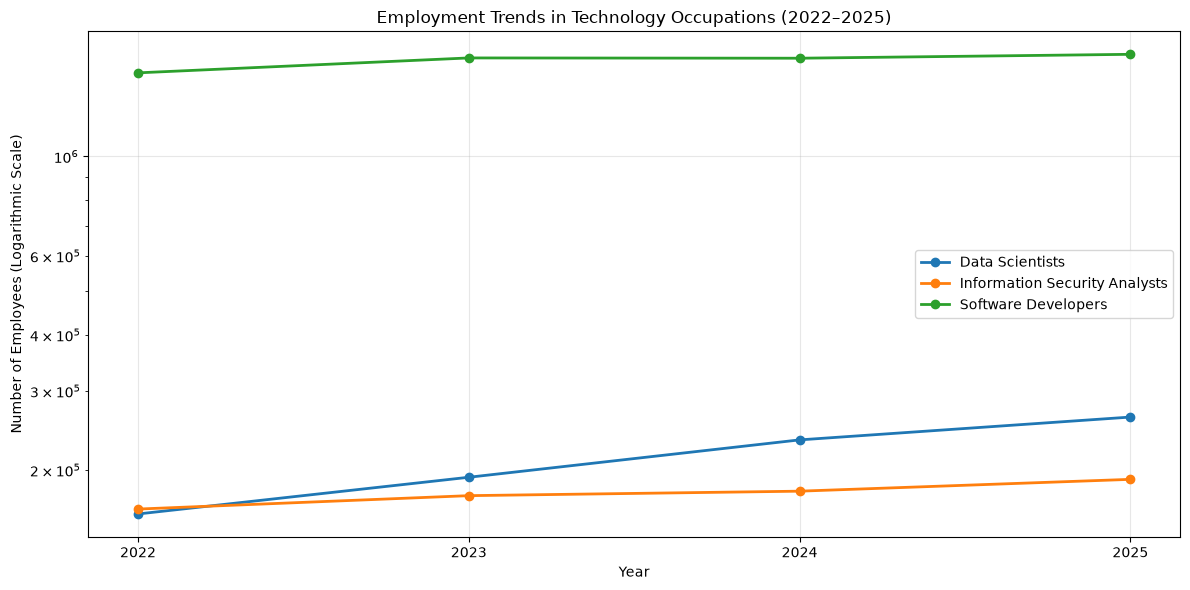

In [22]:
# Visualisation 1: Employment trends over time

employment_pivot = comparison_df.pivot(
    index="Year",
    columns="Occupation",
    values="Employment"
)

plt.figure(figsize=(12, 6))

for occupation in employment_pivot.columns:
    plt.plot(
        employment_pivot.index,
        employment_pivot[occupation],
        marker="o",
        linewidth=2,
        label=occupation
    )

plt.yscale("log")

plt.title("Employment Trends in Technology Occupations (2022–2025)")
plt.xlabel("Year")
plt.ylabel("Number of Employees (Logarithmic Scale)")
plt.xticks([2022, 2023, 2024, 2025])
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
# Load the four BLS employment datasets

data_2022 = pd.read_excel("national_M2022_dl.xlsx")
data_2023 = pd.read_excel("all_data_M_2023.xlsx")
data_2024 = pd.read_excel("national_M2024_dl.xlsx")
data_2025 = pd.read_excel("national_M2025_dl.xlsx")

print("All four datasets loaded successfully!")

All four datasets loaded successfully!


In [8]:
# Check the size of each dataset

print("2022 dataset:", data_2022.shape)
print("2023 dataset:", data_2023.shape)
print("2024 dataset:", data_2024.shape)
print("2025 dataset:", data_2025.shape)

2022 dataset: (1402, 32)
2023 dataset: (413327, 32)
2024 dataset: (1403, 32)
2025 dataset: (1401, 32)


In [9]:
# Display the first five rows of the 2022 dataset

data_2022.head()

,AREA,AREA_TITLE,AREA_TYPE,PRIM_STATE,NAICS,NAICS_TITLE,I_GROUP,OWN_CODE,OCC_CODE,OCC_TITLE,...,H_MEDIAN,H_PCT75,H_PCT90,A_PCT10,A_PCT25,A_MEDIAN,A_PCT75,A_PCT90,ANNUAL,HOURLY
0,99,U.S.,1,US,0,Cross-industry,cross-industry,1235,00-0000,All Occupations,...,22.26,35.32,53.03,27340,33330,46310,73460,110290,NaN,NaN
1,99,U.S.,1,US,0,Cross-industry,cross-industry,1235,11-0000,Management Occupations,...,51.62,78.71,106.03,50290,75350,107360,163710,220550,NaN,NaN
2,99,U.S.,1,US,0,Cross-industry,cross-industry,1235,11-1000,Top Executives,...,48.02,76.96,#,43440,62520,99890,160070,#,NaN,NaN
3,99,U.S.,1,US,0,Cross-industry,cross-industry,1235,11-1010,Chief Executives,...,91.12,#,#,74920,122480,189520,#,#,NaN,NaN
4,99,U.S.,1,US,0,Cross-industry,cross-industry,1235,11-1011,Chief Executives,...,91.12,#,#,74920,122480,189520,#,#,NaN,NaN


In [10]:
# Display all column names

data_2022.columns.tolist()

['AREA',
 'AREA_TITLE',
 'AREA_TYPE',
 'PRIM_STATE',
 'NAICS',
 'NAICS_TITLE',
 'I_GROUP',
 'OWN_CODE',
 'OCC_CODE',
 'OCC_TITLE',
 'O_GROUP',
 'TOT_EMP',
 'EMP_PRSE',
 'JOBS_1000',
 'LOC_QUOTIENT',
 'PCT_TOTAL',
 'PCT_RPT',
 'H_MEAN',
 'A_MEAN',
 'MEAN_PRSE',
 'H_PCT10',
 'H_PCT25',
 'H_MEDIAN',
 'H_PCT75',
 'H_PCT90',
 'A_PCT10',
 'A_PCT25',
 'A_MEDIAN',
 'A_PCT75',
 'A_PCT90',
 'ANNUAL',
 'HOURLY']

In [11]:
# Identify the columns needed for our analysis

important_columns = [
    col for col in data_2022.columns
    if any(word in col for word in ["EMP", "MEDIAN", "MEAN", "OCC", "AREA", "NAICS", "OWN"])
]

print(important_columns)

['AREA', 'AREA_TITLE', 'AREA_TYPE', 'NAICS', 'NAICS_TITLE', 'OWN_CODE', 'OCC_CODE', 'OCC_TITLE', 'TOT_EMP', 'EMP_PRSE', 'H_MEAN', 'A_MEAN', 'MEAN_PRSE', 'H_MEDIAN', 'A_MEDIAN']


In [12]:
# Search for occupations related to AI and technology

data_2022[
    data_2022["OCC_TITLE"].str.contains(
        "Data Scientist|Software Developer|Information Security Analyst",
        case=False,
        na=False
    )
][["OCC_CODE", "OCC_TITLE"]]

,OCC_CODE,OCC_TITLE
136,15-1212,Information Security Analysts
149,15-1252,Software Developers
164,15-2050,Data Scientists
165,15-2051,Data Scientists


In [13]:
# Check the data types of important columns

data_2022[
    ["AREA", "NAICS", "OWN_CODE", "OCC_CODE",
     "OCC_TITLE", "TOT_EMP", "A_MEDIAN"]
].dtypes

AREA          int64
NAICS         int64
OWN_CODE      int64
OCC_CODE        str
OCC_TITLE       str
TOT_EMP       int64
A_MEDIAN     object
dtype: object

In [14]:
# Check the national employment records

data_2022[
    ["AREA", "AREA_TITLE", "NAICS", "OWN_CODE"]
].head()

,AREA,AREA_TITLE,NAICS,OWN_CODE
0,99,U.S.,0,1235
1,99,U.S.,0,1235
2,99,U.S.,0,1235
3,99,U.S.,0,1235
4,99,U.S.,0,1235
